# Speed-reducer shaft limit state: active subspaces of a reliability benchmark

**Paper.** Xiaoping Du (University of Missouri–Rolla, Rolla, Missouri) and Agus Sudjianto (Ford Motor Company, Dearborn, Michigan), "First-Order Saddlepoint Approximation for Reliability Analysis", *AIAA Journal* 42(6):1199–1207, 2004, [doi:10.2514/1.3877](https://doi.org/10.2514/1.3877). The problem is the article's Example 2 (Sec. IV.B, p. 1205).

**Implementation cross-check.** The function `RSSpeedReducerShaft` of the Python package [UQTestFuns](https://github.com/damar-wicaksono/uqtestfuns) 0.7.0 (D. Wicaksono, M. Hecht; MIT licence) implements the same problem; `check_accuracy.py` compares this data set's model with it.

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import special
import active_subspaces as ac
import shaft_model as sm

SEED = 2004
NBOOT = 500
np.set_printoptions(precision=4, suppress=False, linewidth=110)

## Summary

The limit state of a shaft in a speed reducer, strength minus the combined bending–torsion stress, has five independent random inputs: shaft diameter D, span L, external force F (Gumbel), torque T and strength S (uniform). With 1000 Monte Carlo samples and exact gradients, the gradient-based active subspace is one-dimensional in both of the input scalings examined (each input scaled by its standard deviation, or each mapped through its CDF to a standard normal variable), with the torque carrying the largest weight; D and L, whose standard deviations are 0.1 mm, carry almost none. The notebook also estimates the probabilities of the article's Tables 9–11 by Monte Carlo, FORM and SORM: the Monte Carlo values agree with the article's, while the article's FORM and SORM values are not reproduced.

## Active subspaces in brief

For a function $g(\mathbf{x})$ of $m$ normalized inputs with density $\rho$, the matrix $\mathbf{C} = \int \nabla g\, \nabla g^\top \rho\, d\mathbf{x} = \mathbf{W}\Lambda\mathbf{W}^\top$ has eigenvalues $\lambda_1 \ge \dots \ge \lambda_m \ge 0$ that measure the mean squared directional derivative of $g$ along the eigenvectors. If $\lambda_n \gg \lambda_{n+1}$, then $g$ changes mostly along the first $n$ eigenvectors $\mathbf{W}_1$, and $g(\mathbf{x}) \approx h(\mathbf{W}_1^\top \mathbf{x})$ for a function $h$ of the $n$ active variables $\mathbf{y} = \mathbf{W}_1^\top\mathbf{x}$. Here $\mathbf{C}$ is estimated by the Monte Carlo average of the outer products of exact gradients, with bootstrap intervals. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

The limit state is Eq. (34), p. 1205 of the article, "the difference between the strength and the maximum stress":

$$
g(\mathbf{x}) = S - \frac{32}{\pi D^3}\sqrt{\frac{F^2L^2}{16} + T^2},
$$

with S converted from MPa to Pa and D, L from mm to m before evaluation. The article states no unit conversion, but its Tables 10 and 11 use thresholds $4.5 \times 10^7$ and $2.48 \times 10^7$ for $g$ (p. 1205), so $g$ is in Pa; UQTestFuns (`rs_speed_reducer_shaft.py`, function `evaluate`) converts the same way, and the Monte Carlo values below reproduce the article's at all three thresholds. The second term is the equivalent stress of a solid circular shaft under the bending moment $FL/4$ (a midspan load on a simply supported span) and the torque $T$. The quantity of interest is $g$ in Pa; the article's failure event is $g < 0$ (Table 9, p. 1205). Because the formula is closed form, the gradient is exact (`shaft_model.limit_state(X, grad=True)`); it is stored with respect to the physical inputs.

| input | symbol | units | distribution | mean | sd | source |
|---|---|---|---|---|---|---|
| shaft diameter | D | mm | Normal(39, 0.1) | 39 | 0.1 | Table 8, p. 1205 (footnote a: mean and sd) |
| shaft span | L | mm | Normal(400, 0.1) | 400 | 0.1 | Table 8, p. 1205 |
| external force | F | N | Gumbel (max), location 1342.48, scale 272.894 | 1500 | 350 | Table 8, p. 1205 (footnote b: parameters are mean and sd); location and scale from them |
| torque | T | N m | Normal(250, 35) | 250 | 35 | Table 8, p. 1205 |
| strength | S | MPa | Uniform[70, 80] | 75 | 2.887 | Table 8, p. 1205 (footnote c: parameters are the bounds) |

Table 8 gives the marginals only; the article says that in this example "all of the random variables are tractable" (p. 1205) but does not state their dependence. This data set takes them as independent (as UQTestFuns does, "Copulas: Independence"), a reading that the Monte Carlo agreement below supports but cannot prove. The Gumbel (maximum) parameters follow from the mean 1500 N and sd 350 N as scale $\beta = 350\sqrt{6}/\pi$ and location $\mu = 1500 - \gamma\beta$ ($\gamma$ the Euler–Mascheroni constant), as in UQTestFuns' `gumbel_max_beta` and `gumbel_max_mu`.

**Sampling design (this data set's choice).** M = 1000 independent Monte Carlo samples: $\boldsymbol{\xi} \sim N(\mathbf{0}, \mathbf{I}_5)$ and $x_i = F_i^{-1}(\Phi(\xi_i))$, written by `generate_data.py` with seed 2004.

**Two scalings.** The inputs have very different units and distributions, so the subspace depends on how they are normalized. Each input is scaled the same way in each analysis:

* **by sd**: $z_i = (x_i - \mu_i)/\sigma_i$, so $\partial g/\partial z_i = \sigma_i\, \partial g/\partial x_i$ (the `ac.Gaussian` space with the inputs' means and variances is used only as this affine map; the expectation is over the true, non-Gaussian distribution of the samples);
* **through the CDF**: $\xi_i = \Phi^{-1}(F_i(x_i))$, the independent standard normal coordinates of reliability analysis, so $\partial g/\partial \xi_i = (dx_i/d\xi_i)\, \partial g/\partial x_i$ with $dx_i/d\xi_i = \phi(\xi_i)/\rho_i(x_i)$.

For the three normal inputs (D, L, T) the two scalings coincide. They differ for F, whose Gumbel tail makes $dx/d\xi$ grow with $\xi$, and for S, whose bounded support makes $dx/d\xi = 10\,\phi(\xi)$ MPa vanish in the tails.

## Load the data

The files hold the physical inputs, $g$ in Pa, and the gradients with respect to the physical inputs. The cell re-evaluates the model at the stored inputs and compares.

In [2]:
X = np.loadtxt('inputs.csv', delimiter=',')
g = np.loadtxt('outputs.csv', delimiter=',')
G = np.loadtxt('gradients.csv', delimiter=',')
print('inputs', X.shape, 'outputs', g.shape, 'gradients', G.shape)
g_model, G_model = sm.limit_state(X, grad=True)
print(f'model vs files: max |g difference| / max |g| = {np.max(np.abs(g_model - g)) / np.max(np.abs(g)):.0e}, '
      f'max |gradient difference| / max |gradient| = {np.max(np.abs(G_model - G)) / np.max(np.abs(G)):.0e}')
print('sample means ', X.mean(axis=0).round(3), ' (distribution means', sm.MEAN, ')')
print('sample sds   ', X.std(axis=0, ddof=1).round(4), ' (distribution sds', sm.SD.round(4), ')')
print(f'g in [{g.min():.4e}, {g.max():.4e}] Pa; samples with g <= 0: {int(np.sum(g <= 0))}')

inputs (1000, 5) outputs (1000,) gradients (1000, 5)
model vs files: max |g difference| / max |g| = 0e+00, max |gradient difference| / max |gradient| = 0e+00
sample means  [  39.     399.996 1502.791  248.943   75.05 ]  (distribution means [  39.  400. 1500.  250.   75.] )
sample sds    [9.5900e-02 1.0260e-01 3.5161e+02 3.4841e+01 2.8070e+00]  (distribution sds [1.0000e-01 1.0000e-01 3.5000e+02 3.5000e+01 2.8868e+00] )
g in [4.5173e+05, 4.7494e+07] Pa; samples with g <= 0: 0


The model reproduces the files to the printed relative differences. The sample means and standard deviations are close to those of the distributions. None of the 1000 samples fails ($g$ is at least $4.5 \times 10^5$ Pa): failure has a probability of about $8 \times 10^{-4}$ (estimated below), so the subspace describes $g$ over the bulk of the distribution, not the failure region.

The next cell maps the samples to the two scalings and compares the CDF scale factors $dx_i/d\xi_i$ with the standard deviations.

In [3]:
# The two scalings. (a) by sd: z = (x - mean)/sd, dg/dz = sd * dg/dx.
# (b) through the CDF: xi = Phi^{-1}(F(x)), dg/dxi = (dx/dxi) * dg/dx.
Z = sm.to_normal(X)
J = sm.dx_dxi(Z)
grads_sd = G * sm.SD
grads_cdf = G * J
print('mean of (dx/dxi)^2 over the samples / sd^2, per input:', (np.mean(J**2, axis=0) / sm.SD**2).round(4))
print('range of dx/dxi for F (N):', J[:, 2].min().round(1), 'to', J[:, 2].max().round(1), ' sd =', sm.SD[2])
print('range of dx/dxi for S (MPa):', J[:, 4].min().round(3), 'to', J[:, 4].max().round(3), ' sd =', sm.SD[4].round(3))

mean of (dx/dxi)^2 over the samples / sd^2, per input: [1.     1.     1.0714 1.     1.1437]
range of dx/dxi for F (N): 135.2 to 838.7  sd = 350.0
range of dx/dxi for S (MPa): 0.002 to 3.989  sd = 2.887


For D, L and T the CDF scale factor equals the sd. For F, $dx/d\xi$ ranges from 135.2 to 838.7 N over the samples (sd 350 N), and its mean square is 1.0714 times $\sigma_F^2$; for S it ranges from 0.002 to 3.989 MPa (sd 2.887 MPa), with mean square 1.1437 times $\sigma_S^2$.

## Estimate the active subspace

Exact gradients are available at every sample, so the estimator is the Monte Carlo average of gradient outer products (`estimator="as"`), with 500 bootstrap replicates and `SEED` for the resampling. Sign rule (the paper has no active subspace): each $\mathbf{w}_1$ is oriented so that its torque component is positive, so that $g$ decreases (toward failure) along $+\mathbf{w}_1$.

In [4]:
space_sd = ac.Gaussian(sm.MEAN, sm.SD**2, names=list(sm.NAMES))       # used only as x -> (x - mean)/sd
space_cdf = ac.Gaussian(np.zeros(5), np.ones(5), names=list(sm.NAMES))  # xi coordinates are already standard
sub_sd = ac.active_subspace(space=space_sd, X=X, grads=G, nboot=NBOOT, rng=SEED, bootstrap_vectors=2)
sub_cdf = ac.active_subspace(space=space_cdf, X=Z, grads=grads_cdf, nboot=NBOOT, rng=SEED, bootstrap_vectors=2)
e_T = np.zeros((5, 1)); e_T[3] = 1.0          # sign rule: positive torque component
sub_sd = ac.orient(sub_sd, by='reference', reference=np.hstack([e_T, e_T]), columns=1)
sub_cdf = ac.orient(sub_cdf, by='reference', reference=np.hstack([e_T, e_T]), columns=1)
for name, s in (('by sd', sub_sd), ('through the CDF', sub_cdf)):
    lam = s.eigenvalues
    ci = ac.bootstrap_interval(s.bootstrap_eigenvalues)
    print(f'scaling {name}: n chosen by the default rule = {s.n}')
    for k in range(5):
        print(f'   lambda_{k + 1} = {lam[k]:.4e}  (95% bootstrap {ci[0, k]:.3e} to {ci[1, k]:.3e})')
    print('   ratios lambda_k/lambda_{k+1}:', ', '.join(f'{r:.4g}' for r in lam[:-1] / lam[1:]))
    print('   share of the trace left out by n = 1, 2:', ', '.join(f'{lam[k:].sum() / lam.sum():.2e}' for k in (1, 2)))

scaling by sd: n chosen by the default rule = 1
   lambda_1 = 4.4139e+13  (95% bootstrap 4.408e+13 to 4.419e+13)
   lambda_2 = 4.6959e+11  (95% bootstrap 4.209e+11 to 5.173e+11)
   lambda_3 = 2.3419e+09  (95% bootstrap 2.134e+09 to 2.535e+09)
   lambda_4 = 8.6744e+08  (95% bootstrap 7.459e+08 to 9.849e+08)
   lambda_5 = 2.9311e+04  (95% bootstrap 2.477e+04 to 3.345e+04)
   ratios lambda_k/lambda_{k+1}: 94, 200.5, 2.7, 2.959e+04
   share of the trace left out by n = 1, 2: 1.06e-02, 7.19e-05
scaling through the CDF: n chosen by the default rule = 1
   lambda_1 = 4.5260e+13  (95% bootstrap 4.457e+13 to 4.594e+13)
   lambda_2 = 2.8801e+12  (95% bootstrap 2.504e+12 to 3.235e+12)
   lambda_3 = 9.3612e+11  (95% bootstrap 8.618e+11 to 1.019e+12)
   lambda_4 = 1.2106e+09  (95% bootstrap 1.099e+09 to 1.305e+09)
   lambda_5 = 7.6973e+03  (95% bootstrap 6.703e+03 to 8.538e+03)
   ratios lambda_k/lambda_{k+1}: 15.71, 3.077, 773.2, 1.573e+05
   share of the trace left out by n = 1, 2: 7.78e-02, 1.91

In the sd scaling $\lambda_1/\lambda_2 = 94$ and $\lambda_2/\lambda_3 = 200.5$; $n = 1$ leaves out 1.06e-02 of the trace and $n = 2$ leaves out 7.19e-05. Through the CDF the gaps are smaller: $\lambda_1/\lambda_2 = 15.71$ and $\lambda_2/\lambda_3 = 3.077$, with left-out shares 7.78e-02 ($n=1$) and 1.91e-02 ($n=2$). In both scalings $\lambda_5$ (2.9311e+04 and 7.6973e+03 Pa$^2$) is nine to ten orders of magnitude below $\lambda_1$ (4.4139e+13 and 4.5260e+13 Pa$^2$); its eigenvector is the span L (below). The library's default eigenvalue-gap rule picks $n = 1$ in both.

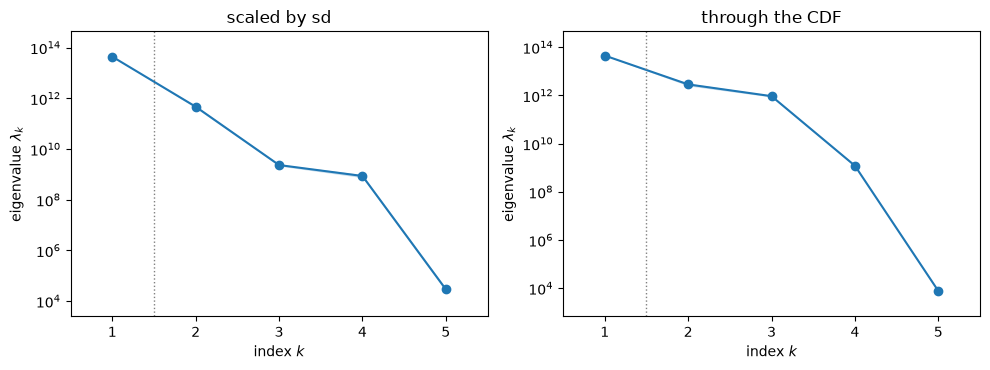

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
ac.plotting.plot_eigenvalues(sub_sd, interval='percentile', ax=axs[0]); axs[0].set_title('scaled by sd')
ac.plotting.plot_eigenvalues(sub_cdf, interval='percentile', ax=axs[1]); axs[1].set_title('through the CDF')
fig.tight_layout()
plt.close(fig)
fig

The 95 % bootstrap intervals of neighbouring eigenvalues do not overlap in either scaling; the closest pairs are λ₃, λ₄ in the sd scaling (ratio 2.7) and λ₂, λ₃ through the CDF (ratio 3.077).

scaling by sd: mean bootstrap subspace distance for n = 1..4: 2.68e-03, 3.31e-03, 2.84e-02, 2.87e-04
scaling through the CDF: mean bootstrap subspace distance for n = 1..4: 9.02e-03, 2.20e-02, 1.09e-03, 7.51e-05


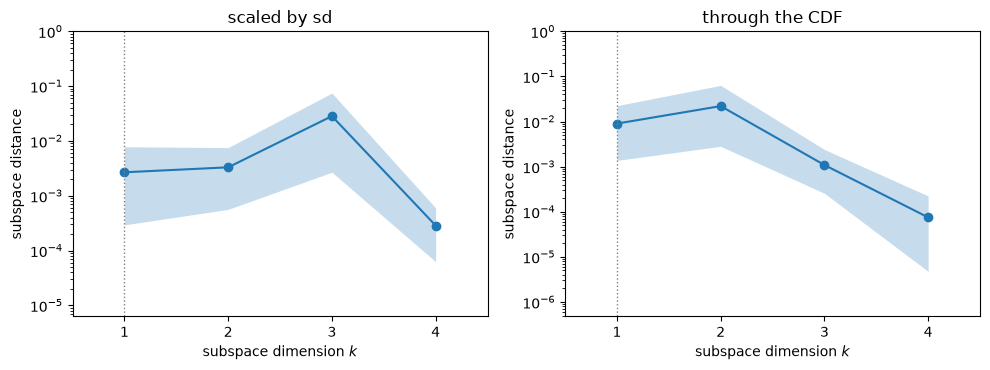

In [6]:
for name, s in (('by sd', sub_sd), ('through the CDF', sub_cdf)):
    d = s.bootstrap_distances
    print(f'scaling {name}: mean bootstrap subspace distance for n = 1..4:',
          ', '.join(f'{v:.2e}' for v in d.mean(axis=0)))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
ac.plotting.plot_subspace_errors(sub_sd, interval='percentile', ax=axs[0]); axs[0].set_title('scaled by sd')
ac.plotting.plot_subspace_errors(sub_cdf, interval='percentile', ax=axs[1]); axs[1].set_title('through the CDF')
fig.tight_layout()
plt.close(fig)
fig

The mean bootstrap subspace distance for $n = 1$ is 2.68e-03 (sd scaling) and 9.02e-03 (CDF scaling), so the one-dimensional subspace is well determined by 1000 gradients. In the CDF scaling the distance for $n = 2$ (2.20e-02) is larger than for $n = 1$, because $\lambda_2/\lambda_3 = 3.077$ is a small gap.

scaling by sd:
   w1 = [-5.820e-02  5.000e-04  4.639e-01  7.698e-01 -4.345e-01]   95% bootstrap: D [-0.0586, -0.0578], L [0.0005, 0.0005], F [0.4586, 0.4690], T [0.7667, 0.7731], S [-0.4348, -0.4342]
   w2 = [-0.004   0.002   0.8527 -0.5222 -0.0143]
scaling through the CDF:
   w1 = [-5.750e-02  5.000e-04  4.914e-01  7.504e-01 -4.383e-01]   95% bootstrap: D [-0.0579, -0.0570], L [0.0005, 0.0005], F [0.4746, 0.5060], T [0.7410, 0.7597], S [-0.4460, -0.4307]
   w2 = [ 8.000e-03  7.000e-04  8.695e-01 -4.502e-01  2.031e-01]
angle between the two w1 (after mapping both to the same input order): 1.94 degrees


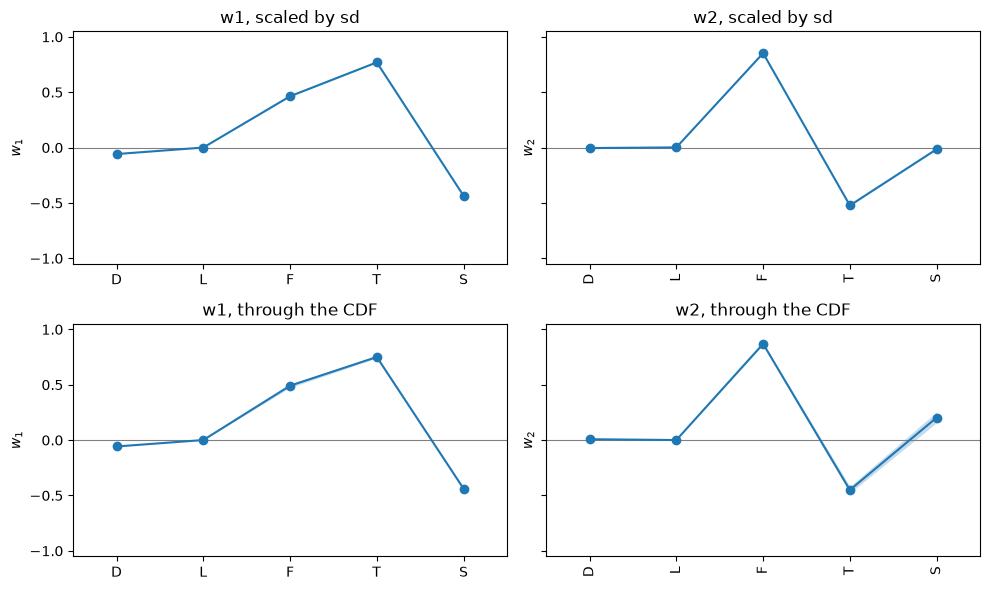

In [7]:
for name, s in (('by sd', sub_sd), ('through the CDF', sub_cdf)):
    W = s.eigenvectors
    ci = ac.bootstrap_interval(s.bootstrap_eigenvectors[:, :, 0])
    print(f'scaling {name}:')
    print('   w1 =', W[:, 0].round(4), '  95% bootstrap: ' + ', '.join(
        f'{n} [{ci[0, i]:.4f}, {ci[1, i]:.4f}]' for i, n in enumerate(sm.NAMES)))
    print('   w2 =', W[:, 1].round(4))
print(f'angle between the two w1 (after mapping both to the same input order): '
      f'{np.degrees(np.arccos(abs(sub_sd.eigenvectors[:, 0] @ sub_cdf.eigenvectors[:, 0]))):.2f} degrees')
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
ac.plotting.plot_eigenvectors(sub_sd, indices=[0, 1], labels=list(sm.NAMES), interval='percentile', ax=axs[0])
ac.plotting.plot_eigenvectors(sub_cdf, indices=[0, 1], labels=list(sm.NAMES), interval='percentile', ax=axs[1])
for a, t in zip(axs.ravel(), ('w1, scaled by sd', 'w2, scaled by sd', 'w1, through the CDF', 'w2, through the CDF')):
    a.set_title(t)
    a.tick_params(labelbottom=True)
fig.tight_layout()
plt.close(fig)
fig

The two $\mathbf{w}_1$ are within 1.94 degrees of each other. In the sd scaling $\mathbf{w}_1 = (-0.0582, 0.0005, 0.4639, 0.7698, -0.4345)$ for (D, L, F, T, S); through the CDF, $(-0.0575, 0.0005, 0.4914, 0.7504, -0.4383)$. Torque has the largest weight, then force and strength with similar magnitudes and opposite signs; $g$ falls as the loads rise and the strength falls. The diameter's weight is small and negative (a larger shaft is stronger) and the span's is about 5e-4. The second eigenvector is mostly F against T in both scalings: it follows the trade-off between bending ($FL/4$) and torsion ($T$) inside the square root.

### What the small variances of D and L do

The sds of D and L are 0.1 mm, 0.256 % and 0.025 % of their means (printed below). The next cell gives each input's share of the trace of $\mathbf{C}$ and, for contrast only, the subspace that would result if every input were scaled by its mean (relative sensitivities), a scaling that ignores the input distributions.

In [8]:
# What the tiny variances of D and L do: each input's share of E[|grad g|^2] (the diagonal of C over its
# trace), in the two scalings and, for contrast only, with each input scaled by its mean (elasticities).
grads_mean = G * sm.MEAN
print('sd / mean, per input (%):', (100 * sm.SD / sm.MEAN).round(3))
for name, A in (('by sd', grads_sd), ('through the CDF', grads_cdf), ('by mean (contrast)', grads_mean)):
    C = A.T @ A / len(A)
    lam, W = np.linalg.eigh(C)
    lam, W = lam[::-1], W[:, ::-1] * np.sign(W[3, ::-1])
    print(f'{name:>20}: shares ' + ', '.join(f'{n} {v:.2e}' for n, v in zip(sm.NAMES, np.diag(C) / np.trace(C)))
          + f'; lambda_1/lambda_2 = {lam[0] / lam[1]:.4g}; w1 = {W[:, 0].round(4)}')
for name, s in (('by sd', sub_sd), ('through the CDF', sub_cdf)):
    print(f'{name:>20}: components of eigenvectors 1-5 on D {s.eigenvectors[0].round(4)}, on L {s.eigenvectors[1].round(4)}')
# The same subspaces with D and L held at their means (F, T, S only)
for name, A in (('by sd', grads_sd), ('through the CDF', grads_cdf)):
    C3 = A[:, 2:].T @ A[:, 2:] / len(A)
    lam3, W3 = np.linalg.eigh(C3)
    w = W3[:, -1] * np.sign(W3[1, -1])
    w5 = (sub_sd if name == 'by sd' else sub_cdf).eigenvectors[2:, 0]
    print(f'{name:>20}, D and L dropped: lambda = {lam3[::-1]}, w1 (F, T, S) = {w.round(4)}, '
          f'angle to the (F, T, S) part of the 5-input w1 {np.degrees(np.arccos(min(1.0, abs(w @ w5) / np.linalg.norm(w5)))):.1e} degrees')

sd / mean, per input (%): [ 0.256  0.025 23.333 14.     3.849]
               by sd: shares D 3.40e-03, L 3.10e-07, F 2.21e-01, T 5.89e-01, S 1.87e-01; lambda_1/lambda_2 = 94; w1 = [-5.820e-02  5.000e-04  4.639e-01  7.698e-01 -4.345e-01]
     through the CDF: shares D 3.09e-03, L 2.82e-07, F 2.67e-01, T 5.36e-01, S 1.94e-01; lambda_1/lambda_2 = 15.71; w1 = [-5.750e-02  5.000e-04  4.914e-01  7.504e-01 -4.383e-01]
  by mean (contrast): shares D 7.58e-01, L 7.26e-03, F 5.93e-03, T 4.40e-02, S 1.85e-01; lambda_1/lambda_2 = 355.9; w1 = [-0.8721  0.0795  0.0756  0.2087 -0.4287]
               by sd: components of eigenvectors 1-5 on D [-0.0582 -0.004   0.9823 -0.1777  0.0099], on L [ 5.000e-04  2.000e-03 -1.020e-02 -9.000e-04  9.999e-01]
     through the CDF: components of eigenvectors 1-5 on D [-0.0575  0.008  -0.0318  0.9978 -0.0029], on L [5.0e-04 7.0e-04 1.0e-04 2.9e-03 1.0e+00]
               by sd, D and L dropped: lambda = [4.3990e+13 4.6958e+11 9.1415e+08], w1 (F, T, S) = [ 0.4647  0

In both distribution-based scalings D accounts for 3.40e-03 (sd) and 3.09e-03 (CDF) of the trace and L for 3.10e-07 and 2.82e-07. Because D and L are normal, both scalings treat them identically, so their weights in $\mathbf{w}_1$ are nearly the same in the two (−0.0582 and −0.0575 for D, 5e-4 for L). What is left of their gradients after the part along $\mathbf{w}_1$ makes up the small eigenvalues: the fifth eigenvector is L to four digits (component 0.9999 and 1.0 in the two scalings), so $\lambda_5$ is the span's own, tiny, contribution, and D is nearly the third eigenvector in the sd scaling (component 0.9823; the signs of these trailing eigenvectors are arbitrary) and the fourth through the CDF (0.9978). With D and L held at their means, the (F, T, S) subspace has the same leading direction, to within 3e-03 degree (1.5e-04 and 2.9e-03 degrees) of the (F, T, S) part of the 5-input $\mathbf{w}_1$ and nearly the same leading eigenvalues. So D and L are inactive and the subspace is determined by F, T and S. Scaled by the means instead, D would dominate ($\mathbf{w}_1$ D component −0.8721, share 7.58e-01), because the stress varies as $D^{-3}$; the shaft is very sensitive to its diameter in relative terms, but the diameter barely varies. The distribution-based scalings measure the second fact.

### Sufficient summary plots

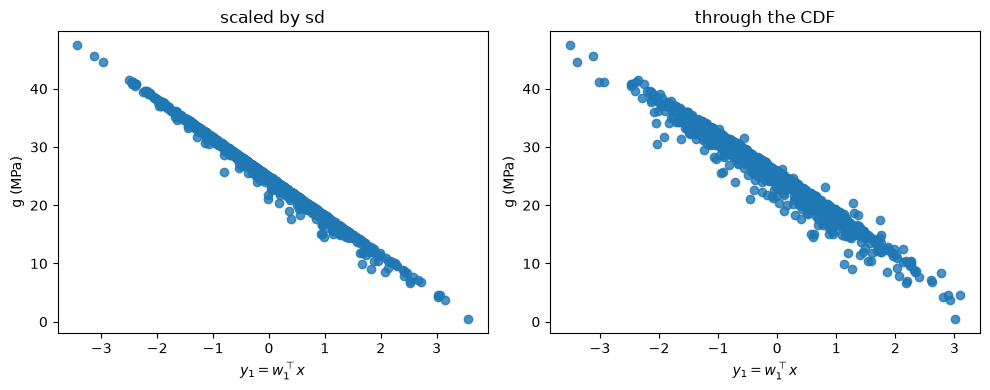

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
ac.plotting.plot_sufficient_summary(sub_sd, X=X, dims=1, f=g / 1e6, qoi_label='g (MPa)', ax=axs[0])
ac.plotting.plot_sufficient_summary(sub_cdf, X=Z, dims=1, f=g / 1e6, qoi_label='g (MPa)', ax=axs[1])
axs[0].set_title('scaled by sd'); axs[1].set_title('through the CDF')
fig.tight_layout()
plt.close(fig)
fig

In the sd scaling $g$ is close to a linear function of $y_1 = \mathbf{w}_1^\top \mathbf{z}$, with a small spread (a few points fall below the line). In the CDF coordinates the spread about the trend is wider: S $= 70 + 10\,\Phi(\xi_S)$ MPa saturates in the tails of $\xi_S$, so $g$ is not linear in $\xi_S$ even though it is linear in S, and the Gumbel map makes it nonlinear in $\xi_F$.

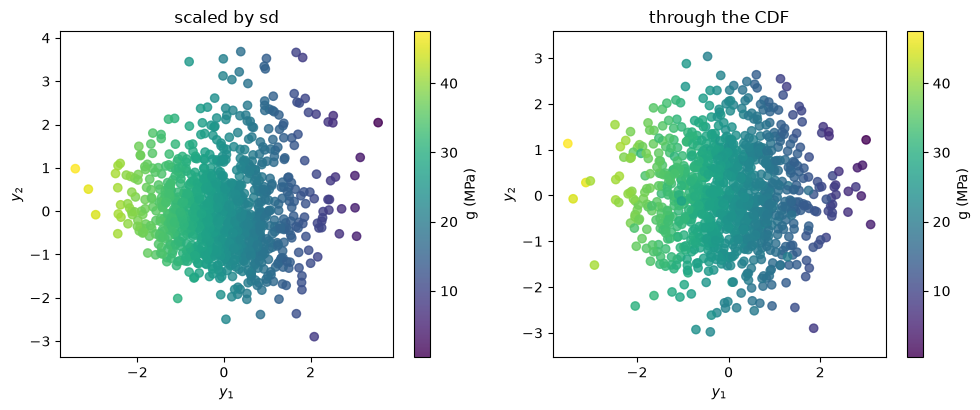

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
ac.plotting.plot_sufficient_summary(sub_sd, X=X, dims=2, f=g / 1e6, qoi_label='g (MPa)', ax=axs[0])
ac.plotting.plot_sufficient_summary(sub_cdf, X=Z, dims=2, f=g / 1e6, qoi_label='g (MPa)', ax=axs[1])
axs[0].set_title('scaled by sd'); axs[1].set_title('through the CDF')
fig.tight_layout()
plt.close(fig)
fig

With two active variables the colour changes mainly along $y_1$; the change along $y_2$ (the F-versus-T direction) at fixed $y_1$ is smaller, as $\lambda_2 \ll \lambda_1$.

## Surrogate on the active variables

Polynomials of degree 1–3 on one or two active variables, fitted to the 1000 samples ($g$ in MPa), with leave-one-out R².

In [11]:
for name, s, XX in (('by sd', sub_sd, X), ('through the CDF', sub_cdf, Z)):
    for n in (1, 2):
        for deg in (1, 2, 3):
            sur = ac.fit_surrogate(X=XX, f=g / 1e6, subspace=ac.with_dimension(s, n), kind='poly', degree=deg)
            print(f'scaling {name}, n = {n}, polynomial degree {deg}: LOO R^2 = {sur.loo_r_squared:.5f}')

scaling by sd, n = 1, polynomial degree 1: LOO R^2 = 0.99355
scaling by sd, n = 1, polynomial degree 2: LOO R^2 = 0.99354
scaling by sd, n = 1, polynomial degree 3: LOO R^2 = 0.99356
scaling by sd, n = 2, polynomial degree 1: LOO R^2 = 0.99473
scaling by sd, n = 2, polynomial degree 2: LOO R^2 = 0.99989
scaling by sd, n = 2, polynomial degree 3: LOO R^2 = 0.99994
scaling through the CDF, n = 1, polynomial degree 1: LOO R^2 = 0.96262
scaling through the CDF, n = 1, polynomial degree 2: LOO R^2 = 0.96335
scaling through the CDF, n = 1, polynomial degree 3: LOO R^2 = 0.96331
scaling through the CDF, n = 2, polynomial degree 1: LOO R^2 = 0.96254
scaling through the CDF, n = 2, polynomial degree 2: LOO R^2 = 0.98929
scaling through the CDF, n = 2, polynomial degree 3: LOO R^2 = 0.99088


Sd scaling: one variable gives LOO R² = 0.99354 for a quadratic (0.99355 linear), two variables give 0.99989 (quadratic). CDF scaling: one variable gives 0.96335 (quadratic), two give 0.98929 (quadratic) and 0.99088 (cubic).

**Chosen dimension: n = 1 in both scalings.** In the sd scaling the gap $\lambda_1/\lambda_2 = 94$, the subspace error 2.68e-03 and the one-variable LOO R² 0.99354 all support it; a second variable adds about 0.006 to R². Through the CDF the gap $\lambda_1/\lambda_2 = 15.71$ still supports $n = 1$ (left-out share 7.78e-02, LOO R² 0.96335), but the next ratio $\lambda_2/\lambda_3 = 3.077$ is comparable, so a two-dimensional subspace in those coordinates is not cleanly separated from the third direction.

## Failure probability

The article gives $P\{g < c\}$ at three thresholds: $c = 0$, the failure probability (Table 9), $c = 4.5 \times 10^7$ Pa (Table 10, "Probability at the tails of distribution"), and $c = 2.48 \times 10^7$ Pa (Table 11, "Probability near the median"), each by FORM, SORM, its first-order saddlepoint approximation (FOSPA) and Monte Carlo with $10^6$ samples (p. 1205). This notebook estimates all three by Monte Carlo with $2 \times 10^7$ new samples from the model's own sampler, and by FORM: the design point is the point of the surface $g = c$ closest to the origin in the standard normal coordinates $\boldsymbol{\xi}$ (SLSQP with exact gradients, 23 starting points, the smallest $\beta$ kept), and $P\{g<c\} \approx \Phi(-\beta)$ when the origin lies on the side $g > c$, $\Phi(\beta)$ otherwise.

In [12]:
# Probabilities P[g < c] at the thresholds of the article's Tables 9-11 (c = 0, 4.5e7, 2.48e7 Pa),
# by Monte Carlo with the model's own sampler (new draws, seed SEED + 1).
THRESH = (0.0, 4.5e7, 2.48e7)
MCS_PAPER = (7.850e-4, 0.99938, 0.5038)     # Du and Sudjianto (2004), Tables 9, 10, 11, MCS column, N = 1e6
rng = np.random.default_rng(SEED + 1)
counts, n_tot = np.zeros(3, int), 0
for _ in range(20):
    Xs, _ = sm.sample(10**6, rng)
    gs = sm.limit_state(Xs)
    counts += [int(np.sum(gs < c)) for c in THRESH]
    n_tot += len(Xs)
p_mc = counts / n_tot
hw_mc = 1.96 * np.sqrt(p_mc * (1 - p_mc) / n_tot)
for c, p, h, pr in zip(THRESH, p_mc, hw_mc, MCS_PAPER):
    hr = 1.96 * np.sqrt(pr * (1 - pr) / 10**6)
    print(f'P[g < {c:.3g} Pa]: Monte Carlo N = {n_tot:.0e}: {p:.5g}, 95% interval [{p - h:.5g}, {p + h:.5g}]; '
          f'article MCS {pr:.5g} (95% binomial interval with N = 1e6 [{pr - hr:.5g}, {pr + hr:.5g}]); '
          f'difference {1.96 * (pr - p) / np.hypot(h, hr):.2f} combined standard errors')
pf, hw = p_mc[0], hw_mc[0]
# FORM in the CDF (standard normal) coordinates, at each threshold; several starting points, smallest beta kept
def form_best(c):
    r = np.random.default_rng(SEED)
    starts = [None, np.array([0.0, 0.0, -1.0, -1.0, 1.0]), np.full(5, 1e-3)] + [r.standard_normal(5) for _ in range(20)]
    best, betas = None, []
    for z0 in starts:
        try:
            z, b, a = sm.form(start=z0, threshold=c)
        except RuntimeError:
            continue
        betas.append(b)
        if best is None or b < best[1]:
            best = (z, b, a)
    return best, np.array(betas)

g_origin = sm.limit_state(sm.from_normal(np.zeros((1, 5))))[0]
p_form = []
for c in THRESH:
    (z, b, a), betas = form_best(c)
    p_form.append(special.ndtr(-b) if g_origin > c else special.ndtr(b))
    print(f'FORM, threshold {c:.3g} Pa: beta = {b:.5f} ({len(betas)} converged starts, beta range '
          f'{betas.min():.5f} to {betas.max():.5f}); P[g < c] = {p_form[-1]:.5g}')
(xi_star, beta, alpha), _ = form_best(0.0)
x_star = sm.from_normal(xi_star)[0]
print(f'FORM, c = 0: Phi(-beta) = {special.ndtr(-beta):.4e}')
print('design point x* =', ', '.join(f'{n} {v:.4g} {u}' for n, v, u in zip(sm.NAMES, x_star, sm.UNITS)))
print('alpha =', alpha.round(4))
print(f'angle between alpha and w1 (through the CDF): '
      f'{np.degrees(np.arccos(abs(alpha @ sub_cdf.eigenvectors[:, 0]))):.1f} degrees')

P[g < 0 Pa]: Monte Carlo N = 2e+07: 0.00077205, 95% interval [0.00075988, 0.00078422]; article MCS 0.000785 (95% binomial interval with N = 1e6 [0.00073011, 0.00083989]); difference 0.45 combined standard errors
P[g < 4.5e+07 Pa]: Monte Carlo N = 2e+07: 0.99936, 95% interval [0.99935, 0.99937]; article MCS 0.99938 (95% binomial interval with N = 1e6 [0.99933, 0.99943]); difference 0.82 combined standard errors
P[g < 2.48e+07 Pa]: Monte Carlo N = 2e+07: 0.5039, 95% interval [0.50368, 0.50412]; article MCS 0.5038 (95% binomial interval with N = 1e6 [0.50282, 0.50478]); difference -0.20 combined standard errors


FORM, threshold 0 Pa: beta = 3.19455 (22 converged starts, beta range 3.19455 to 3.19455); P[g < c] = 0.00070025


FORM, threshold 4.5e+07 Pa: beta = 3.04145 (19 converged starts, beta range 3.04145 to 3.04145); P[g < c] = 0.99882
FORM, threshold 2.48e+07 Pa: beta = 0.08976 (23 converged starts, beta range 0.08976 to 0.08976); P[g < c] = 0.46424


FORM, c = 0: Phi(-beta) = 7.0025e-04
design point x* = D 38.99 mm, L 400 mm, F 3049 N, T 288.6 N m, S 72.17 MPa
alpha = [-4.630e-02  8.000e-04  9.049e-01  3.449e-01 -2.449e-01]
angle between alpha and w1 (through the CDF): 35.6 degrees


Monte Carlo gives $P\{g<0\}$ = 7.7205e-04 with 95 % interval [7.5988e-04, 7.8422e-04]. The article's Monte Carlo value 7.850e-4 (Table 9, $N = 10^6$) has its own 95 % binomial interval [7.3011e-04, 8.3989e-04], which contains this run's estimate; the two differ by 0.45 combined standard errors. At the other two thresholds this run gives 0.99936 against the article's 0.99938 (Table 10; 0.82 combined standard errors) and 0.5039 against 0.5038 (Table 11; −0.20). These matches check the formula, the units and all five marginals together.

FORM finds one design point for each threshold (every converged start gives the same $\beta$). For $c = 0$, $\beta$ = 3.19455 and $\Phi(-\beta)$ = 7.0025e-04, a little below the Monte Carlo value (FORM's linearization of the limit-state surface at the design point is an approximation, not a bound). The design point has F = 3049 N (far in the Gumbel tail), T = 288.6 N m and S = 72.17 MPa. The FORM direction $\boldsymbol{\alpha}$ is dominated by F (0.9049) and is 35.6 degrees from the CDF-scaled $\mathbf{w}_1$: the active subspace averages the gradient over the whole distribution, where torque matters most, while FORM looks at the failure region, which the heavy-tailed force controls. At the other thresholds FORM gives 0.99882 ($\beta$ = 3.04145) and 0.46424 ($\beta$ = 0.08976).

SORM corrects the FORM estimate at $c = 0$ with the principal curvatures of the surface at the design point.

In [13]:
# SORM at the c = 0 design point: principal curvatures from the Hessian of g in xi
# (central differences of the exact xi-gradient, step 1e-4), Breitung and Hohenbichler-Rackwitz formulas.
def grad_xi(u):
    u = np.atleast_2d(u)
    _, Gu = sm.limit_state(sm.from_normal(u), grad=True)
    return (Gu * sm.dx_dxi(u))[0]

gr = grad_xi(xi_star)
ng = np.linalg.norm(gr)
H = np.column_stack([(grad_xi(xi_star + 1e-4 * e) - grad_xi(xi_star - 1e-4 * e)) / 2e-4 for e in np.eye(5)])
H = (H + H.T) / 2
Q, _ = np.linalg.qr(np.column_stack([-gr / ng, np.eye(5)[:, :4]]))
kappa = np.linalg.eigvalsh(Q[:, 1:].T @ H @ Q[:, 1:] / ng)      # > 0: surface curves away from the origin
p1 = special.ndtr(-beta)
p_breitung = p1 * np.prod(1 / np.sqrt(1 + beta * kappa))
psi = np.exp(-beta**2 / 2) / np.sqrt(2 * np.pi) / p1
p_hr = p1 * np.prod(1 / np.sqrt(1 + psi * kappa))
print('principal curvatures:', np.array2string(kappa, precision=3))
print(f'SORM, P[g < 0]: Breitung {p_breitung:.4e}, Hohenbichler-Rackwitz {p_hr:.4e} (FORM {p1:.4e})')

principal curvatures: [-1.084e-01  1.964e-07  1.006e-04  1.676e-01]
SORM, P[g < 0]: Breitung 6.9886e-04, Hohenbichler-Rackwitz 7.0473e-04 (FORM 7.0025e-04)


The curvatures are small (the largest in magnitude is 1.676e-01), so the second-order estimates, 6.9886e-04 (Breitung) and 7.0473e-04 (Hohenbichler–Rackwitz), stay close to FORM's 7.0025e-04 and to the Monte Carlo value.

## Check of the gradients

In [14]:
# Gradient check: exact gradients against central differences at 20 samples.
h = 1e-6 * sm.MEAN
Gfd = np.column_stack([(sm.limit_state(X[:20] + h[j] * np.eye(5)[j]) - sm.limit_state(X[:20] - h[j] * np.eye(5)[j]))
                       / (2 * h[j]) for j in range(5)])
rel = np.linalg.norm((Gfd - G[:20]) * sm.SD, axis=1) / np.linalg.norm(G[:20] * sm.SD, axis=1)
print(f'max relative error of the shipped gradients vs central differences (20 samples): {rel.max():.1e}')

max relative error of the shipped gradients vs central differences (20 samples): 2.3e-10


The shipped gradients agree with central differences to the printed relative error (2.3e-10), the size of the differences' truncation and round-off error. `generate_data.py` repeats the check at all 1000 samples.

## Comparison with the paper

Probabilities $P\{g < c\}$ from the article's Tables 9–11 (p. 1205; Monte Carlo there with $N = 10^6$, the number of function evaluations in parentheses) and from this notebook (Monte Carlo with $N = 2\times10^7$ and 95 % intervals; FORM; SORM at $c = 0$ only).

| quantity | article (Table, p. 1205) | this notebook |
|---|---|---|
| $P\{g<0\}$, Monte Carlo | 7.850 × 10⁻⁴ (Table 9) | 7.7205e-04 [7.5988e-04, 7.8422e-04] |
| $P\{g<0\}$, FORM | 7.007 × 10⁻⁷ (1472; Table 9) | 7.0025e-04 ($\beta$ = 3.19455) |
| $P\{g<0\}$, SORM | 4.3581 × 10⁻⁷ (1514; Table 9) | 6.9886e-04 (Breitung), 7.0473e-04 (Hohenbichler–Rackwitz) |
| $P\{g<0\}$, FOSPA | 6.1754 × 10⁻⁴ (102; Table 9) | not computed |
| $P\{g<4.5\times10^7\}$, Monte Carlo | 0.99938 (Table 10) | 0.99936 [0.99935, 0.99937] |
| $P\{g<4.5\times10^7\}$, FORM / SORM / FOSPA | 0.96798 (212) / 0.97406 (254) / 0.99927 (55) (Table 10) | FORM 0.99882 ($\beta$ = 3.04145) |
| $P\{g<2.48\times10^7\}$, Monte Carlo | 0.5038 (Table 11) | 0.5039 [0.50368, 0.50412] |
| $P\{g<2.48\times10^7\}$, FORM / SORM / FOSPA | 0.1538 (93) / 0.1406 (135) / 0.4825 (43) (Table 11) | FORM 0.46424 ($\beta$ = 0.08976) |
| $P\{g<0\}$, sequential surrogate (Li et al. 2018) | 7.52 × 10⁻³ (44; Table 9 of that paper, as listed by UQTestFuns, not checked) | not computed |
| active subspace | not reported | $n = 1$; $\lambda_1/\lambda_2$ = 94 (sd), 15.71 (CDF) |

The Monte Carlo values agree with the article's at all three thresholds, within their sampling error. The article's FORM and SORM values are not reproduced at any threshold: at $c = 0$ the article prints 7.007 × 10⁻⁷ (FORM) and 4.3581 × 10⁻⁷ (SORM), while this notebook's FORM and SORM give about 7.0 × 10⁻⁴, close to the Monte Carlo value; at the other two thresholds the article's FORM values (0.96798, 0.1538) also differ from this notebook's (0.99882, 0.46424). This notebook finds a single design point at each threshold. The article does not give its design points or reliability indices, so the source of the differences (for example the transformation to standard normal variables or the search) cannot be determined from it. The Li et al. (2018) value is about ten times the Monte Carlo estimate and was not checked.

## References

* X. Du and A. Sudjianto, "First-Order Saddlepoint Approximation for Reliability Analysis", *AIAA Journal* 42(6):1199–1207, 2004. [doi:10.2514/1.3877](https://doi.org/10.2514/1.3877)
* D. Wicaksono and M. Hecht, "UQTestFuns: A Python3 library of uncertainty quantification (UQ) test functions", *Journal of Open Source Software* 8(90):5671, 2023. [doi:10.21105/joss.05671](https://doi.org/10.21105/joss.05671)
* X. Li, C. Gong, L. Gu, W. Gao, Z. Jing and H. Su, "A sequential surrogate method for reliability analysis based on radial basis function", *Structural Safety* 73:42–53, 2018. [doi:10.1016/j.strusafe.2018.02.005](https://doi.org/10.1016/j.strusafe.2018.02.005)
* P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

## Acknowledgments

From the article (p. 1207): "Support for the first author from University of Missouri System Research Board, 943, is gratefully acknowledged."